# Классификация Oxford Pets

Обучим сеть для классификации исходного датасета [Oxford-IIIT Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/). Загрузите датасет с Kaggle.

In [27]:
# Получаем датасет
import glob
import os
import subprocess

try:
    # Оригинальный датасет с Kaggle. Публичные датасеты kagglehub скачивает без авторизации.
    import kagglehub
    DATA_ROOT = kagglehub.dataset_download('tanlikesmath/the-oxfordiiit-pet-dataset')
except Exception as error:
    # Запасной вариант: тот же самый архив с сайта авторов датасета
    print('Не удалось скачать с Kaggle:', error)
    if not os.path.isdir('images'):
        subprocess.run('wget -q https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz '
                       '&& tar xfz images.tar.gz && rm images.tar.gz', shell=True, check=True)
    DATA_ROOT = 'images'

print('Датасет лежит в:', DATA_ROOT)

Using Colab cache for faster access to the 'the-oxfordiiit-pet-dataset' dataset.
Датасет лежит в: /kaggle/input/the-oxfordiiit-pet-dataset


Для визуализации изображений используйте функцию:

In [28]:
import matplotlib.pyplot as plt
import os
from PIL import Image
import numpy as np

def display_images(l,titles=None,fontsize=12):
    n=len(l)
    fig,ax = plt.subplots(1,n)
    for i,im in enumerate(l):
        ax[i].imshow(im)
        ax[i].axis('off')
        if titles is not None:
            ax[i].set_title(titles[i],fontsize=fontsize)
    fig.set_size_inches(fig.get_size_inches()*n)
    plt.tight_layout()
    plt.show()

## План работы

1. Подготовить данные: метки пород из имён файлов, stratified split на train / test.
2. Transfer Learning: обучить три классификатора пород на основе предобученных **VGG-16**, **VGG-19** и **ResNet-50**.
3. Сравнить их на тесте и выбрать лучшую сеть.
4. Для лучшей сети: точность «кошки против собак», confusion matrix, top-3 и top-5 accuracy.
5. Grad-CAM: матрица 5×5 с картами активации (5 изображений × 5 классов).
6. Zero-shot классификация с помощью **CLIP** и текстовых промптов: кошка/собака и породы, матрицы ошибок.

Ноутбук рассчитан на Google Colab с GPU (*Среда выполнения → Сменить среду выполнения → T4 GPU*). На CPU обучение VGG займёт часы.

In [29]:
import time

import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
use_amp = device == 'cuda'   # смешанная точность (float16) ускоряет работу на GPU примерно вдвое
print('Устройство:', device)

Устройство: cuda


## 1. Подготовка данных

Все картинки лежат в одной папке, порода зашита в имя файла: `Abyssinian_12.jpg`, `american_bulldog_7.jpg`.

* Порода — всё, что стоит до последнего `_`.
* В этом датасете породы **кошек написаны с заглавной буквы**, а породы **собак — со строчной**. Так получаем метку «кошка/собака».

In [30]:
files = glob.glob(os.path.join(DATA_ROOT, '**', '*.jpg'), recursive=True)
# В разных версиях архива папка images может встречаться дважды - оставляем каждый файл один раз
files = {os.path.basename(f): f for f in files if not os.path.basename(f).startswith('.')}
files = np.array([files[name] for name in sorted(files)])

breeds = [os.path.basename(f).rsplit('_', 1)[0] for f in files]
classes = sorted(set(breeds))                       # заглавные буквы идут раньше: сначала кошки, потом собаки
labels = np.array([classes.index(b) for b in breeds])
num_classes = len(classes)

species = np.array([0 if c[0].isupper() else 1 for c in classes])   # 0 - кошка, 1 - собака
SPECIES_NAMES = ['cat', 'dog']

print(f'Изображений: {len(files)}, пород: {num_classes} '
      f'(кошек: {(species == 0).sum()}, собак: {(species == 1).sum()})')
print(classes)

Изображений: 7390, пород: 37 (кошек: 12, собак: 25)
['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'Egyptian_Mau', 'Maine_Coon', 'Persian', 'Ragdoll', 'Russian_Blue', 'Siamese', 'Sphynx', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'boxer', 'chihuahua', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'miniature_pinscher', 'newfoundland', 'pomeranian', 'pug', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']


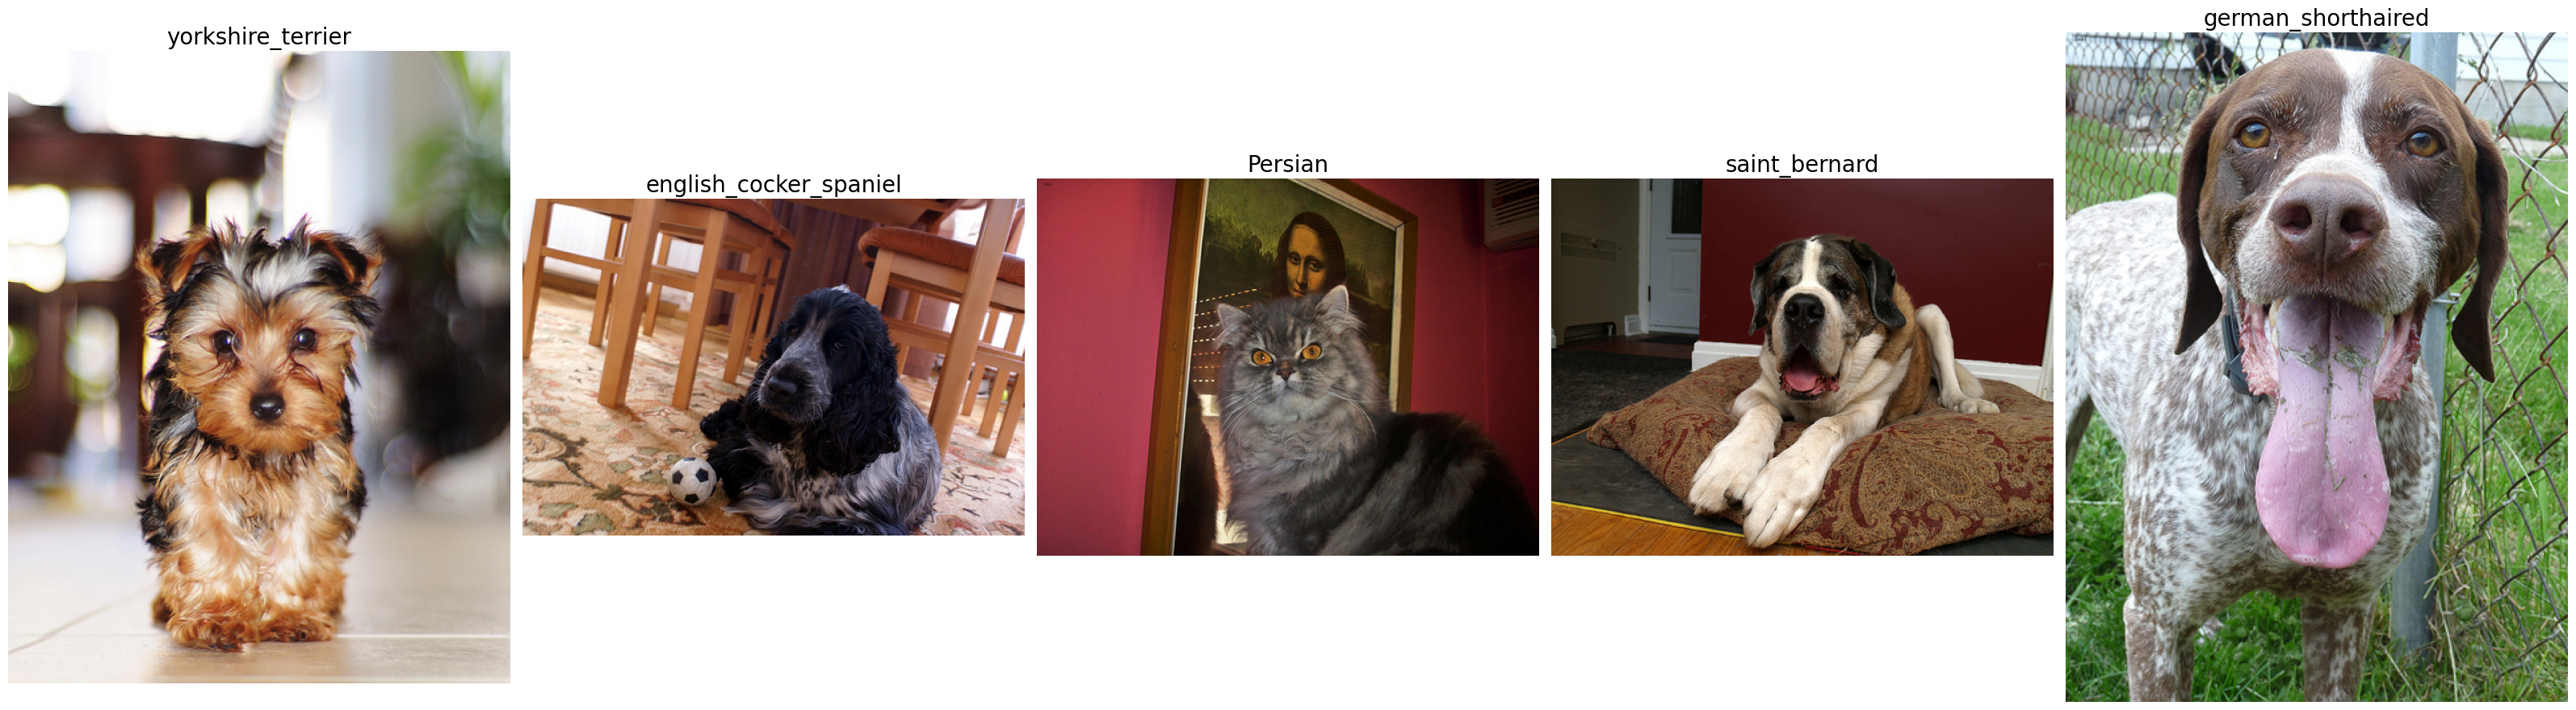

In [31]:
sample = np.random.RandomState(SEED).choice(len(files), 5, replace=False)
display_images([Image.open(files[i]).convert('RGB') for i in sample],
               titles=[classes[labels[i]] for i in sample], fontsize=20)

### Stratified split

20% изображений откладываем в тест. `stratify=labels` сохраняет долю каждой породы в обеих частях.

In [32]:
train_idx, test_idx = train_test_split(np.arange(len(files)), test_size=0.2, stratify=labels,
                                       random_state=SEED)
print(f'train: {len(train_idx)}, test: {len(test_idx)}')

split_table = pd.DataFrame({'train': np.bincount(labels[train_idx], minlength=num_classes),
                            'test': np.bincount(labels[test_idx], minlength=num_classes)}, index=classes)
split_table['доля test'] = (split_table['test'] / split_table.sum(axis=1)).round(3)
display(split_table.T)

train: 5912, test: 1478


,Abyssinian,Bengal,Birman,Bombay,British_Shorthair,Egyptian_Mau,Maine_Coon,Persian,Ragdoll,Russian_Blue,...,newfoundland,pomeranian,pug,saint_bernard,samoyed,scottish_terrier,shiba_inu,staffordshire_bull_terrier,wheaten_terrier,yorkshire_terrier
train,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,...,160.0,160.0,160.0,160.0,160.0,159.000,160.0,153.000,160.0,160.0
test,40.0,40.0,40.0,40.0,40.0,40.0,40.0,40.0,40.0,40.0,...,40.0,40.0,40.0,40.0,40.0,40.000,40.0,38.000,40.0,40.0
доля test,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,...,0.2,0.2,0.2,0.2,0.2,0.201,0.2,0.199,0.2,0.2


### Предобработка

Предобученные сети ждут картинку 224×224, нормированную средним и отклонением ImageNet.

* **train**: случайный кроп с изменением масштаба + отражение (аугментации);
* **test**: изменение размера до 256 и центральный кроп 224.

In [33]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
imagenet_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    imagenet_norm,
])
test_resize = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
test_tf = transforms.Compose([test_resize, transforms.ToTensor(), imagenet_norm])


class PetDataset(Dataset):
    def __init__(self, idx, transform):
        self.idx, self.transform = idx, transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        image = Image.open(files[j]).convert('RGB')   # в датасете есть несколько не-RGB картинок
        return self.transform(image), int(labels[j])


train_dl = DataLoader(PetDataset(train_idx, train_tf), batch_size=64, shuffle=True, drop_last=True,
                      num_workers=2, pin_memory=True)
test_dl = DataLoader(PetDataset(test_idx, test_tf), batch_size=128, num_workers=2, pin_memory=True)

x, y = next(iter(train_dl))
print('Батч изображений:', tuple(x.shape), '| батч меток:', tuple(y.shape))

Батч изображений: (64, 3, 224, 224) | батч меток: (64,)


## 2. Transfer Learning

Идея: сеть, обученная на ImageNet (1000 классов, 1.2 млн картинок), уже умеет выделять полезные признаки — края, текстуры, шерсть, морды. Мы **замораживаем** все её веса и обучаем только новый последний слой на 37 пород.

* У VGG-16 / VGG-19 заменяем последний слой классификатора `classifier[6]` (4096 → 37).
* У ResNet-50 заменяем слой `fc` (2048 → 37).

Обучается только этот слой, поэтому хватает нескольких эпох.

In [34]:
def build_model(name):
    if name == 'vgg16':
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    elif name == 'vgg19':
        model = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
    elif name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    else:
        raise ValueError(name)

    for p in model.parameters():          # замораживаем предобученные веса
        p.requires_grad = False

    if name.startswith('vgg'):            # новый слой создаётся с requires_grad=True
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    else:
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)


@torch.no_grad()
def predict(model, loader):
    """Логиты и правильные ответы для всего загрузчика."""
    model.eval()
    outputs, targets = [], []
    for x, y in loader:
        with torch.autocast(device_type=device, enabled=use_amp):
            out = model(x.to(device))
        outputs.append(out.float().cpu())
        targets.append(y)
    return torch.cat(outputs), torch.cat(targets)


def topk_accuracy(logits, targets, k):
    topk = logits.topk(k, dim=1).indices
    return (topk == targets[:, None]).any(dim=1).float().mean().item()


def train_model(name, epochs=5, lr=1e-3):
    model = build_model(name)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history = {'train_loss': [], 'train_acc': [], 'test_acc': []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device, enabled=use_amp):
                out = model(x)
                loss = F.cross_entropy(out, y)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
        logits, targets = predict(model, test_dl)
        test_acc = (logits.argmax(1) == targets).float().mean().item()
        history['train_loss'].append(loss_sum / total)
        history['train_acc'].append(correct / total)
        history['test_acc'].append(test_acc)
        print(f'{name} | эпоха {epoch}/{epochs}: train loss {loss_sum / total:.3f}, '
              f'train acc {correct / total:.3f}, test acc {test_acc:.3f} ({time.time() - start:.0f} с)')
    return {'model': model, 'history': history, 'logits': logits, 'targets': targets,
            'test_acc': test_acc, 'time': time.time() - start,
            'trainable': sum(p.numel() for p in trainable),
            'total': sum(p.numel() for p in model.parameters())}

In [35]:
EPOCHS = 5
results = {}

In [36]:
results['vgg16'] = train_model('vgg16', EPOCHS)

vgg16 | эпоха 1/5: train loss 0.665, train acc 0.805, test acc 0.915 (58 с)
vgg16 | эпоха 2/5: train loss 0.286, train acc 0.907, test acc 0.913 (107 с)
vgg16 | эпоха 3/5: train loss 0.255, train acc 0.913, test acc 0.919 (155 с)
vgg16 | эпоха 4/5: train loss 0.231, train acc 0.918, test acc 0.922 (203 с)
vgg16 | эпоха 5/5: train loss 0.215, train acc 0.927, test acc 0.922 (253 с)


In [37]:
results['vgg19'] = train_model('vgg19', EPOCHS)

vgg19 | эпоха 1/5: train loss 0.637, train acc 0.815, test acc 0.915 (51 с)
vgg19 | эпоха 2/5: train loss 0.297, train acc 0.901, test acc 0.913 (103 с)
vgg19 | эпоха 3/5: train loss 0.241, train acc 0.918, test acc 0.915 (153 с)
vgg19 | эпоха 4/5: train loss 0.245, train acc 0.913, test acc 0.917 (202 с)
vgg19 | эпоха 5/5: train loss 0.220, train acc 0.918, test acc 0.917 (253 с)


In [38]:
results['resnet50'] = train_model('resnet50', EPOCHS)

resnet50 | эпоха 1/5: train loss 1.147, train acc 0.761, test acc 0.890 (46 с)
resnet50 | эпоха 2/5: train loss 0.366, train acc 0.908, test acc 0.917 (90 с)
resnet50 | эпоха 3/5: train loss 0.286, train acc 0.922, test acc 0.928 (135 с)
resnet50 | эпоха 4/5: train loss 0.246, train acc 0.930, test acc 0.934 (181 с)
resnet50 | эпоха 5/5: train loss 0.215, train acc 0.939, test acc 0.923 (226 с)


## 3. Сравнение классификаторов

,test accuracy,top-3,top-5,"всего параметров, млн","обучаемых параметров, тыс","время обучения, с"
vgg16,0.9222,0.9946,0.9986,134.4,151.6,253.0
vgg19,0.9175,0.9953,0.9993,139.7,151.6,253.0
resnet50,0.9229,0.9939,0.9973,23.6,75.8,226.0


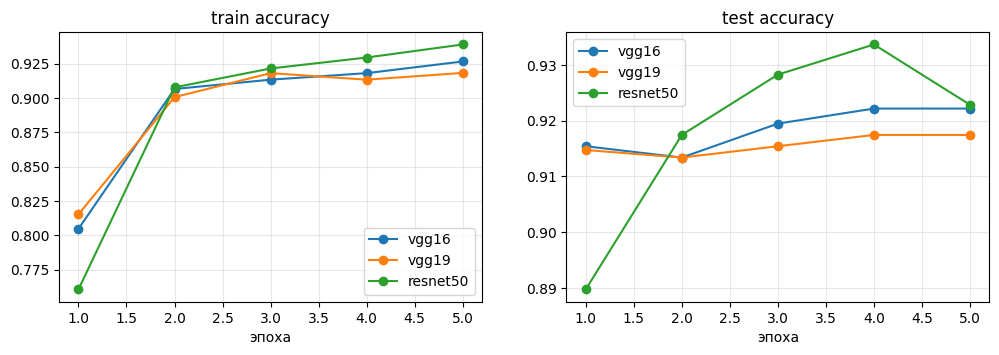

Лучшая сеть: resnet50, test accuracy = 0.9229


In [39]:
comparison = pd.DataFrame({
    name: {'test accuracy': round(r['test_acc'], 4),
           'top-3': round(topk_accuracy(r['logits'], r['targets'], 3), 4),
           'top-5': round(topk_accuracy(r['logits'], r['targets'], 5), 4),
           'всего параметров, млн': round(r['total'] / 1e6, 1),
           'обучаемых параметров, тыс': round(r['trainable'] / 1e3, 1),
           'время обучения, с': round(r['time'])}
    for name, r in results.items()}).T
display(comparison)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, r in results.items():
    ax[0].plot(range(1, EPOCHS + 1), r['history']['train_acc'], marker='o', label=name)
    ax[1].plot(range(1, EPOCHS + 1), r['history']['test_acc'], marker='o', label=name)
for a, title in zip(ax, ('train accuracy', 'test accuracy')):
    a.set_title(title)
    a.set_xlabel('эпоха')
    a.legend()
    a.grid(alpha=0.3)
plt.show()

best_name = max(results, key=lambda name: results[name]['test_acc'])
print(f'Лучшая сеть: {best_name}, test accuracy = {results[best_name]["test_acc"]:.4f}')

## 4. Лучшая сеть: подробные метрики

* **Кошки против собак**: берём предсказанную породу и проверяем только вид животного.
* **Top-3 / top-5**: правильная порода среди 3 (5) самых вероятных.

In [40]:
best = results[best_name]
best_model = best['model']
logits, targets = best['logits'], best['targets']
pred = logits.argmax(1)

species_t = torch.tensor(species)
best_acc = (pred == targets).float().mean().item()
best_top3 = topk_accuracy(logits, targets, 3)
best_top5 = topk_accuracy(logits, targets, 5)
best_binary = (species_t[pred] == species_t[targets]).float().mean().item()

print(f'Сеть: {best_name}')
print(f'Точность определения породы (top-1): {best_acc:.4f}')
print(f'Top-3 accuracy:                      {best_top3:.4f}')
print(f'Top-5 accuracy:                      {best_top5:.4f}')
print(f'Кошки против собак:                  {best_binary:.4f}')

Сеть: resnet50
Точность определения породы (top-1): 0.9229
Top-3 accuracy:                      0.9939
Top-5 accuracy:                      0.9973
Кошки против собак:                  0.9973


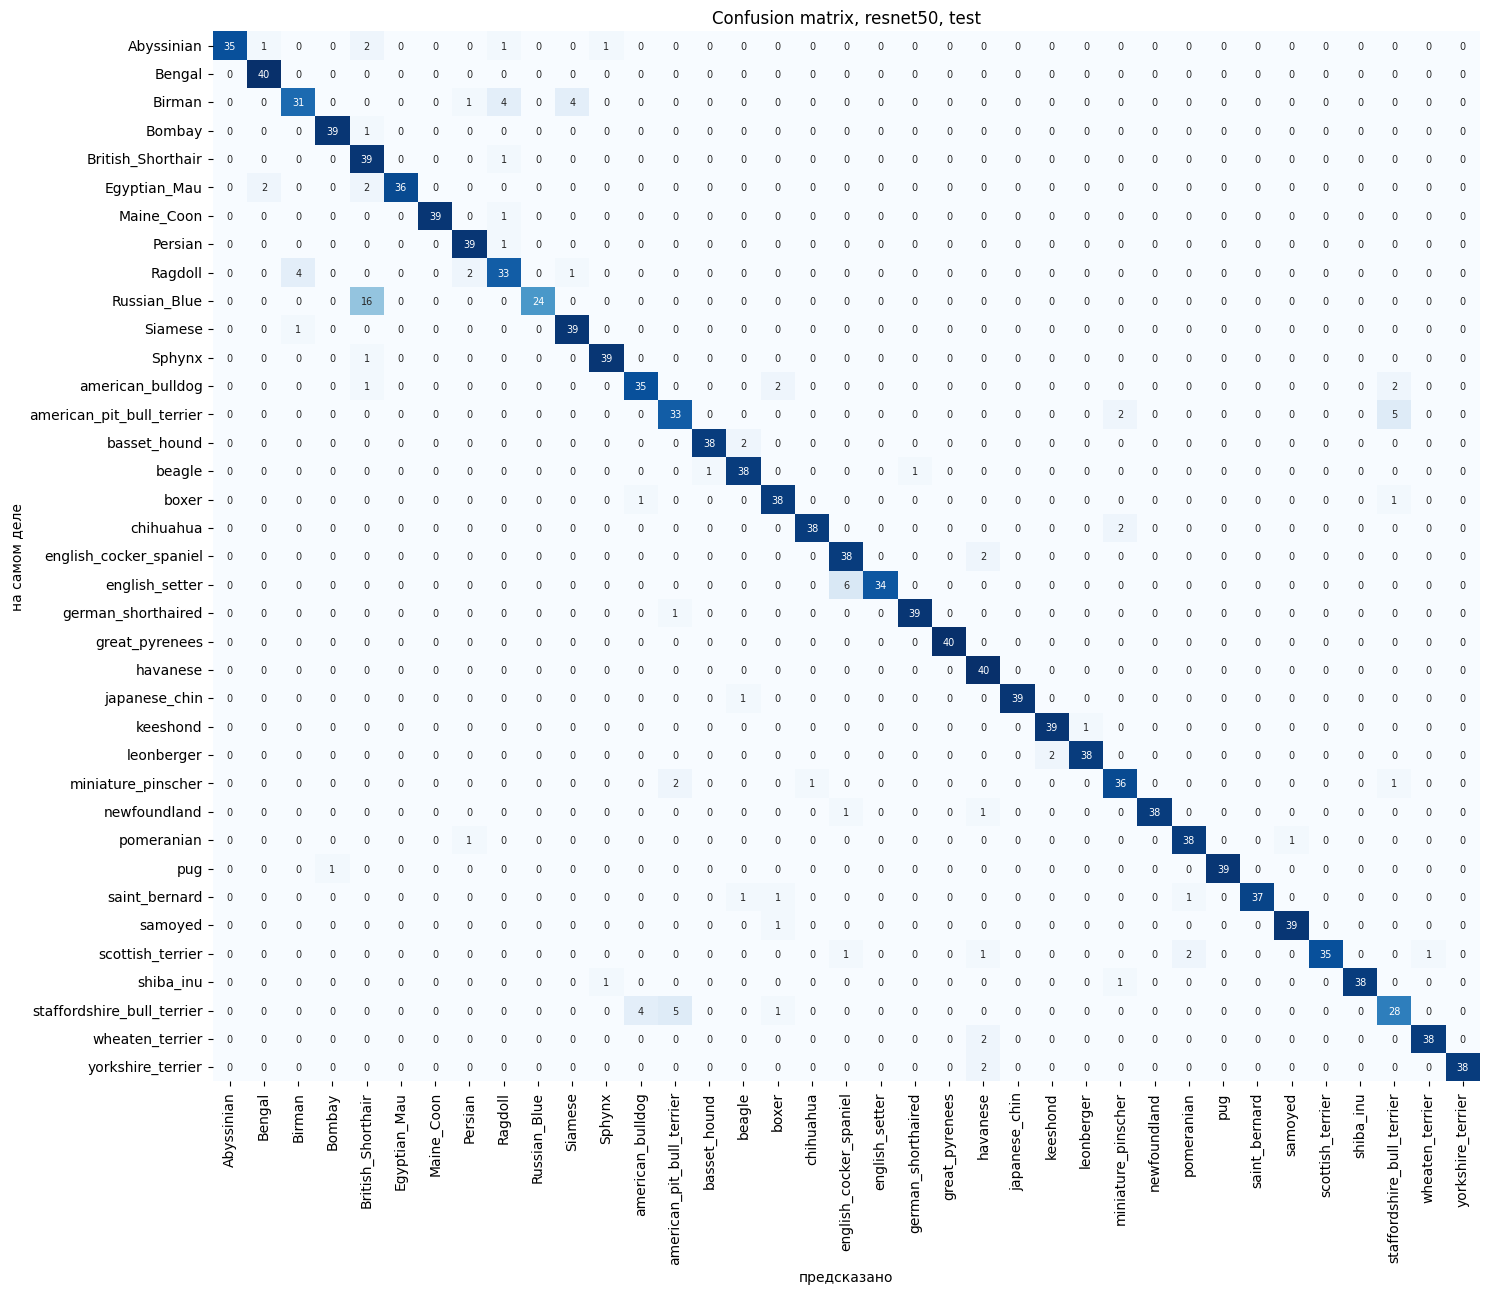

In [41]:
def plot_confusion(cm, names, title, size=15):
    plt.figure(figsize=(size, size * 0.87))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=names, yticklabels=names, annot_kws={'size': 7})
    plt.xlabel('предсказано')
    plt.ylabel('на самом деле')
    plt.title(title)
    plt.tight_layout()
    plt.show()


def most_confused(cm, names, n=10):
    errors = cm.copy()
    np.fill_diagonal(errors, 0)
    rows, cols = np.unravel_index(np.argsort(errors, axis=None)[::-1][:n], errors.shape)
    keep = errors[rows, cols] > 0                 # не показываем пары, которые ни разу не перепутались
    rows, cols = rows[keep], cols[keep]
    return pd.DataFrame({'настоящая порода': [names[i] for i in rows],
                         'предсказана как': [names[j] for j in cols],
                         'сколько раз': errors[rows, cols]})


cm = confusion_matrix(targets.numpy(), pred.numpy(), labels=np.arange(num_classes))
plot_confusion(cm, classes, f'Confusion matrix, {best_name}, test')

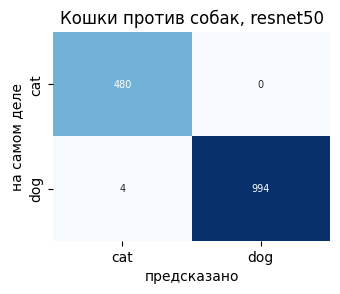

Самые частые ошибки:


,настоящая порода,предсказана как,сколько раз
0,Russian_Blue,British_Shorthair,16
1,english_setter,english_cocker_spaniel,6
2,american_pit_bull_terrier,staffordshire_bull_terrier,5
3,staffordshire_bull_terrier,american_pit_bull_terrier,5
4,Birman,Siamese,4
5,Ragdoll,Birman,4
6,staffordshire_bull_terrier,american_bulldog,4
7,Birman,Ragdoll,4
8,Abyssinian,British_Shorthair,2
9,miniature_pinscher,american_pit_bull_terrier,2


In [42]:
cm_species = confusion_matrix(species[targets.numpy()], species[pred.numpy()])
plot_confusion(cm_species, SPECIES_NAMES, f'Кошки против собак, {best_name}', size=3.5)

print('Самые частые ошибки:')
display(most_confused(cm, classes))

## 5. Grad-CAM

Grad-CAM показывает, какие области картинки сильнее всего повлияли на оценку выбранного класса.

1. Прогоняем картинку через свёрточную часть сети и берём карты признаков **последнего свёрточного слоя** `A` (у ResNet-50 это 2048 карт 7×7, у VGG — 512 карт 14×14).
2. Считаем градиент оценки нужного класса по этим картам.
3. Усредняем градиент по пространству — получаем вес (важность) каждой карты.
4. Складываем карты с этими весами и применяем ReLU (оставляем только то, что *повышает* оценку класса).
5. Растягиваем результат до размера картинки и накладываем как тепловую карту.

Чтобы получить градиент по промежуточным картам, прямой проход разбит на две части: `features` (до последнего свёрточного слоя) и `head` (всё, что после).

In [43]:
def split_forward(model):
    """Возвращает две функции: картинка -> карты признаков и карты признаков -> логиты."""
    if isinstance(model, models.ResNet):
        def features(x):
            x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
            return model.layer4(model.layer3(model.layer2(model.layer1(x))))

        def head(a):
            return model.fc(torch.flatten(model.avgpool(a), 1))
    else:  # VGG: последний слой features - это MaxPool, его относим к "голове"
        def features(x):
            return model.features[:-1](x)

        def head(a):
            a = model.avgpool(model.features[-1](a))
            return model.classifier(torch.flatten(a, 1))
    return features, head


def grad_cam(model, x, class_id):
    """x - тензор 1x3xHxW. Возвращает карту HxW в диапазоне [0, 1] и вероятность класса."""
    model.eval()
    features, head = split_forward(model)
    with torch.no_grad():
        activations = features(x)
    activations.requires_grad_(True)                       # хотим градиент по картам признаков
    out = head(activations)
    out[0, class_id].backward()
    weights = activations.grad.mean(dim=(2, 3), keepdim=True)   # важность каждой карты
    cam = F.relu((weights * activations).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), out.softmax(dim=1)[0, class_id].item()

### Матрица 5×5

Берём 5 пород и по одному тестовому изображению каждой из них.

* **Строка** — изображение (его настоящая порода подписана слева).
* **Столбец** — класс, для которого строится карта.
* На диагонали — карта для настоящей породы. В заголовке каждой ячейки — вероятность `p`, которую сеть даёт этому классу.

Каждая карта нормирована на свой максимум, поэтому яркость карт в разных ячейках сравнивать нельзя — для этого и подписана вероятность.

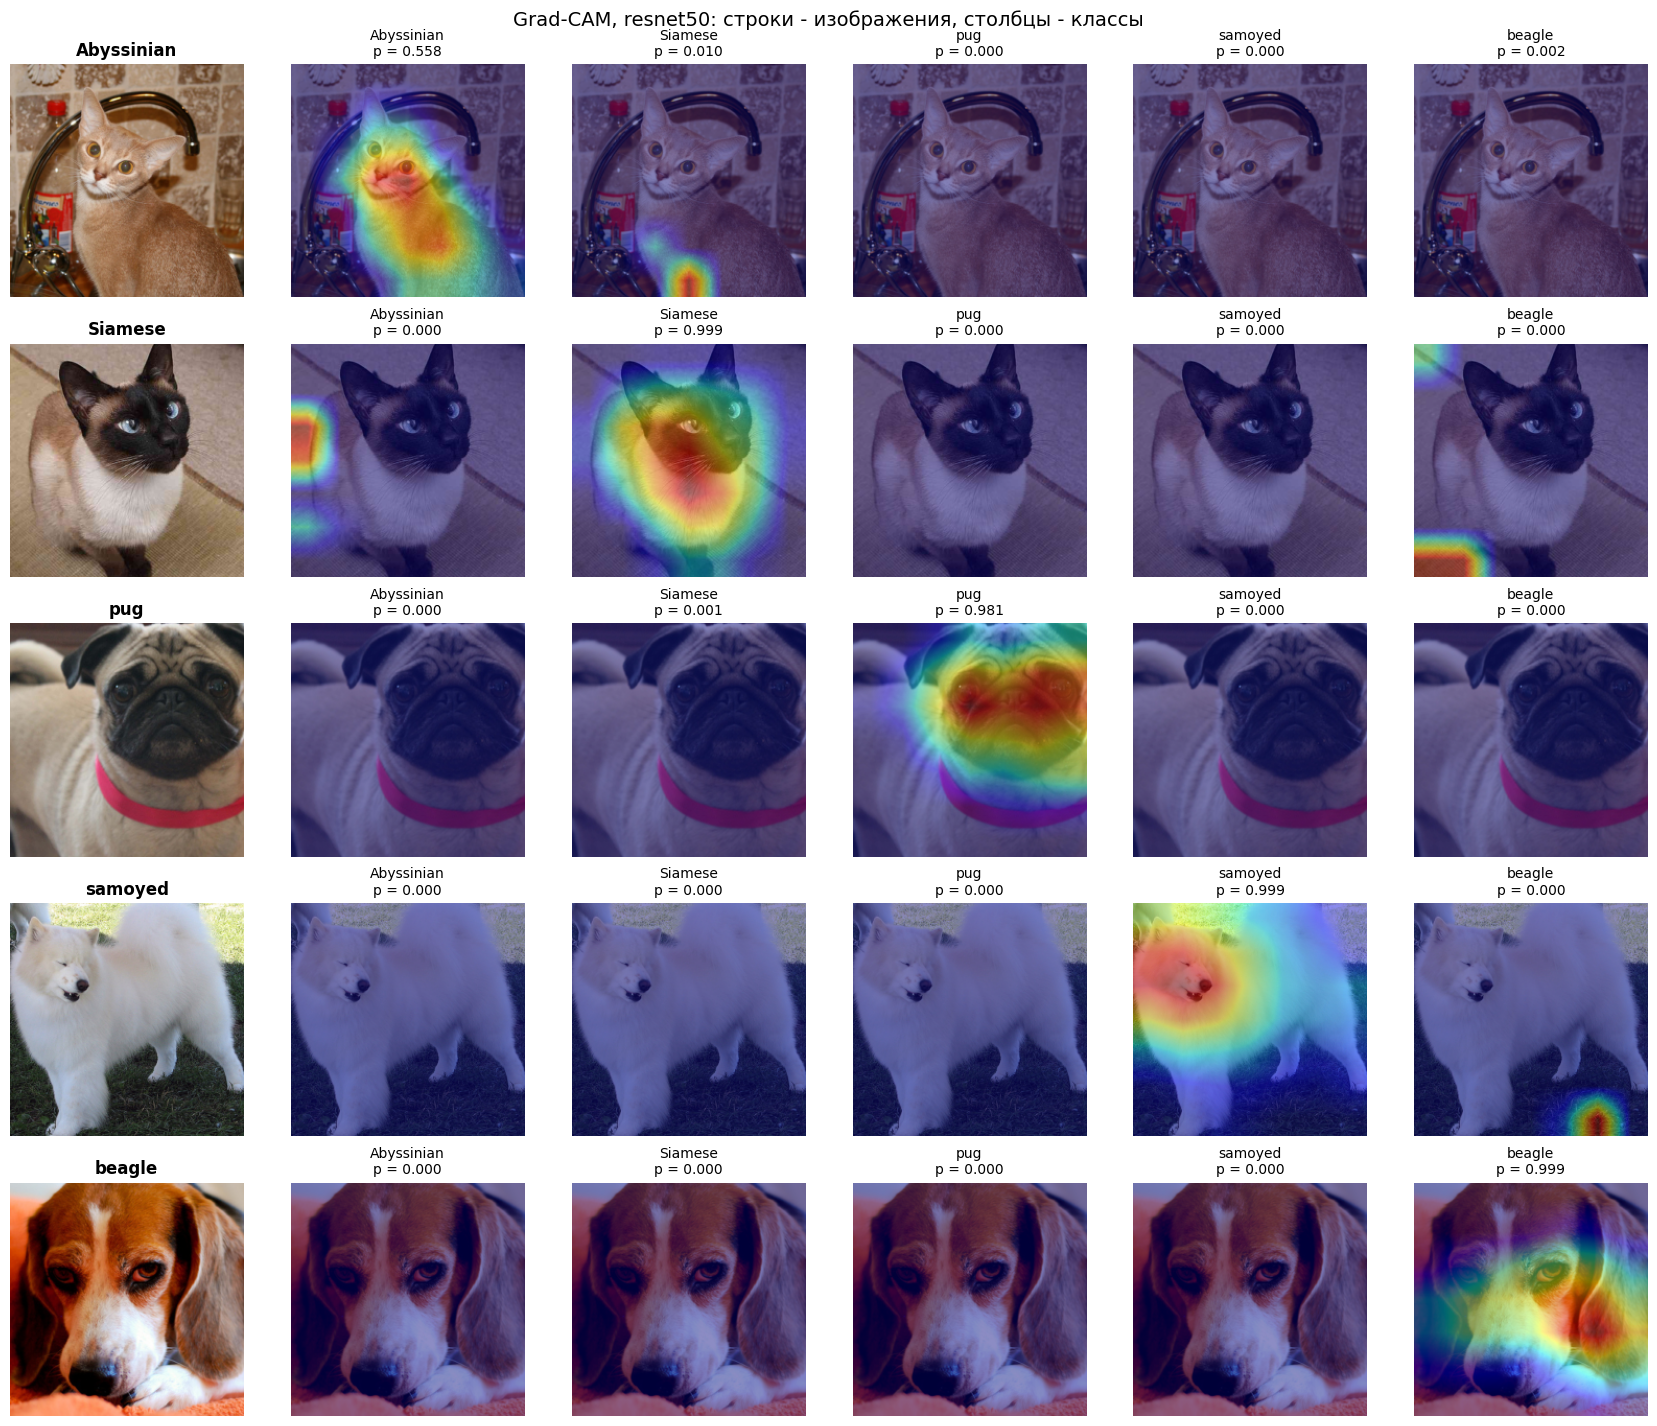

In [44]:
wanted = ['Abyssinian', 'Siamese', 'pug', 'samoyed', 'beagle']
cam_classes = [classes.index(name) for name in wanted if name in classes]
cam_classes += [c for c in range(num_classes) if c not in cam_classes][:5 - len(cam_classes)]

# по одному тестовому изображению каждого выбранного класса
cam_images = [test_idx[np.where(labels[test_idx] == c)[0][0]] for c in cam_classes]

fig, ax = plt.subplots(5, 6, figsize=(17, 14.5))
for row, image_id in enumerate(cam_images):
    image = test_resize(Image.open(files[image_id]).convert('RGB'))
    x = imagenet_norm(transforms.ToTensor()(image)).unsqueeze(0).to(device)

    ax[row, 0].imshow(image)
    ax[row, 0].set_title(f'{classes[labels[image_id]]}', fontsize=12, fontweight='bold')
    for col, class_id in enumerate(cam_classes, start=1):
        cam, prob = grad_cam(best_model, x, class_id)
        ax[row, col].imshow(image)
        ax[row, col].imshow(cam, cmap='jet', alpha=0.45, vmin=0, vmax=1)
        ax[row, col].set_title(f'{classes[class_id]}\np = {prob:.3f}', fontsize=10)
for a in ax.ravel():
    a.axis('off')
plt.suptitle(f'Grad-CAM, {best_name}: строки - изображения, столбцы - классы', fontsize=14)
plt.tight_layout()
plt.show()

## 6. CLIP: zero-shot классификация текстовыми промптами

[CLIP](https://github.com/openai/CLIP) обучен сопоставлять картинки и подписи к ним: у него есть кодировщик изображений и кодировщик текста, которые отображают картинку и текст в одно общее пространство.

Чтобы классифицировать **без обучения** (zero-shot):

1. Для каждого класса пишем текстовый промпт, например `a photo of a pug dog, a type of pet`.
2. Кодируем все промпты и картинку.
3. Выбираем класс, чей промпт ближе всего к картинке по косинусной близости.

Точность считаем на той же тестовой выборке, что и для обученных сетей, — так результаты можно сравнивать напрямую.

In [45]:
!pip -q install git+https://github.com/openai/CLIP.git

  Preparing metadata (setup.py) ... done


In [46]:
import clip

# освобождаем память GPU от сетей, которые больше не нужны
for name in list(results):
    if name != best_name:
        results[name]['model'] = None
torch.cuda.empty_cache()

clip_model, clip_preprocess = clip.load('ViT-B/32', device=device)
clip_model.eval()
print('Доступные варианты CLIP:', clip.available_models())

Доступные варианты CLIP: ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


In [47]:
@torch.no_grad()
def encode_texts(prompts):
    features = clip_model.encode_text(clip.tokenize(prompts).to(device)).float()
    return features / features.norm(dim=-1, keepdim=True)


@torch.no_grad()
def encode_images(loader):
    features, targets = [], []
    for x, y in loader:
        f = clip_model.encode_image(x.to(device)).float()
        features.append((f / f.norm(dim=-1, keepdim=True)).cpu())
        targets.append(y)
    return torch.cat(features), torch.cat(targets)


# Те же тестовые изображения, но с предобработкой CLIP (свои размер и нормировка)
clip_dl = DataLoader(PetDataset(test_idx, clip_preprocess), batch_size=128, num_workers=2)
image_features, clip_targets = encode_images(clip_dl)
print('Признаки изображений:', tuple(image_features.shape))

Признаки изображений: (1478, 512)


### 6.1. Кошка или собака

CLIP, кошки против собак: 0.9986


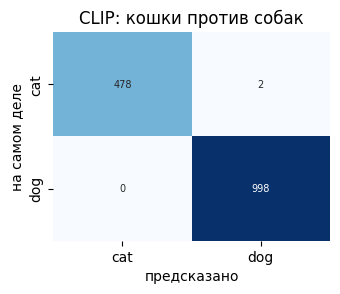

In [48]:
binary_prompts = ['a photo of a cat', 'a photo of a dog']
binary_scores = image_features @ encode_texts(binary_prompts).cpu().T
clip_binary_pred = binary_scores.argmax(1)
clip_binary_true = species_t[clip_targets]
clip_binary_acc = (clip_binary_pred == clip_binary_true).float().mean().item()
print(f'CLIP, кошки против собак: {clip_binary_acc:.4f}')

plot_confusion(confusion_matrix(clip_binary_true.numpy(), clip_binary_pred.numpy()),
               SPECIES_NAMES, 'CLIP: кошки против собак', size=3.5)

### 6.2. Породы

В промпт добавляем и породу, и вид животного: названия вроде `boxer`, `Bombay` или `Persian` сами по себе многозначны, а `boxer dog` и `Persian cat` — уже нет.

In [49]:
def breed_prompt(class_id):
    breed = classes[class_id].replace('_', ' ')
    return f'a photo of a {breed} {SPECIES_NAMES[species[class_id]]}, a type of pet'


breed_prompts = [breed_prompt(c) for c in range(num_classes)]
print(*breed_prompts[:3], '...', sep='\n')

clip_logits = 100 * image_features @ encode_texts(breed_prompts).cpu().T
clip_pred = clip_logits.argmax(1)

clip_acc = (clip_pred == clip_targets).float().mean().item()
clip_top3 = topk_accuracy(clip_logits, clip_targets, 3)
clip_top5 = topk_accuracy(clip_logits, clip_targets, 5)
clip_binary_from_breed = (species_t[clip_pred] == species_t[clip_targets]).float().mean().item()

print(f'CLIP, точность по породам (top-1): {clip_acc:.4f}')
print(f'CLIP, top-3: {clip_top3:.4f}, top-5: {clip_top5:.4f}')
print(f'CLIP, кошки против собак через предсказанную породу: {clip_binary_from_breed:.4f}')

a photo of a Abyssinian cat, a type of pet
a photo of a Bengal cat, a type of pet
a photo of a Birman cat, a type of pet
...
CLIP, точность по породам (top-1): 0.8978
CLIP, top-3: 0.9871, top-5: 0.9959
CLIP, кошки против собак через предсказанную породу: 1.0000


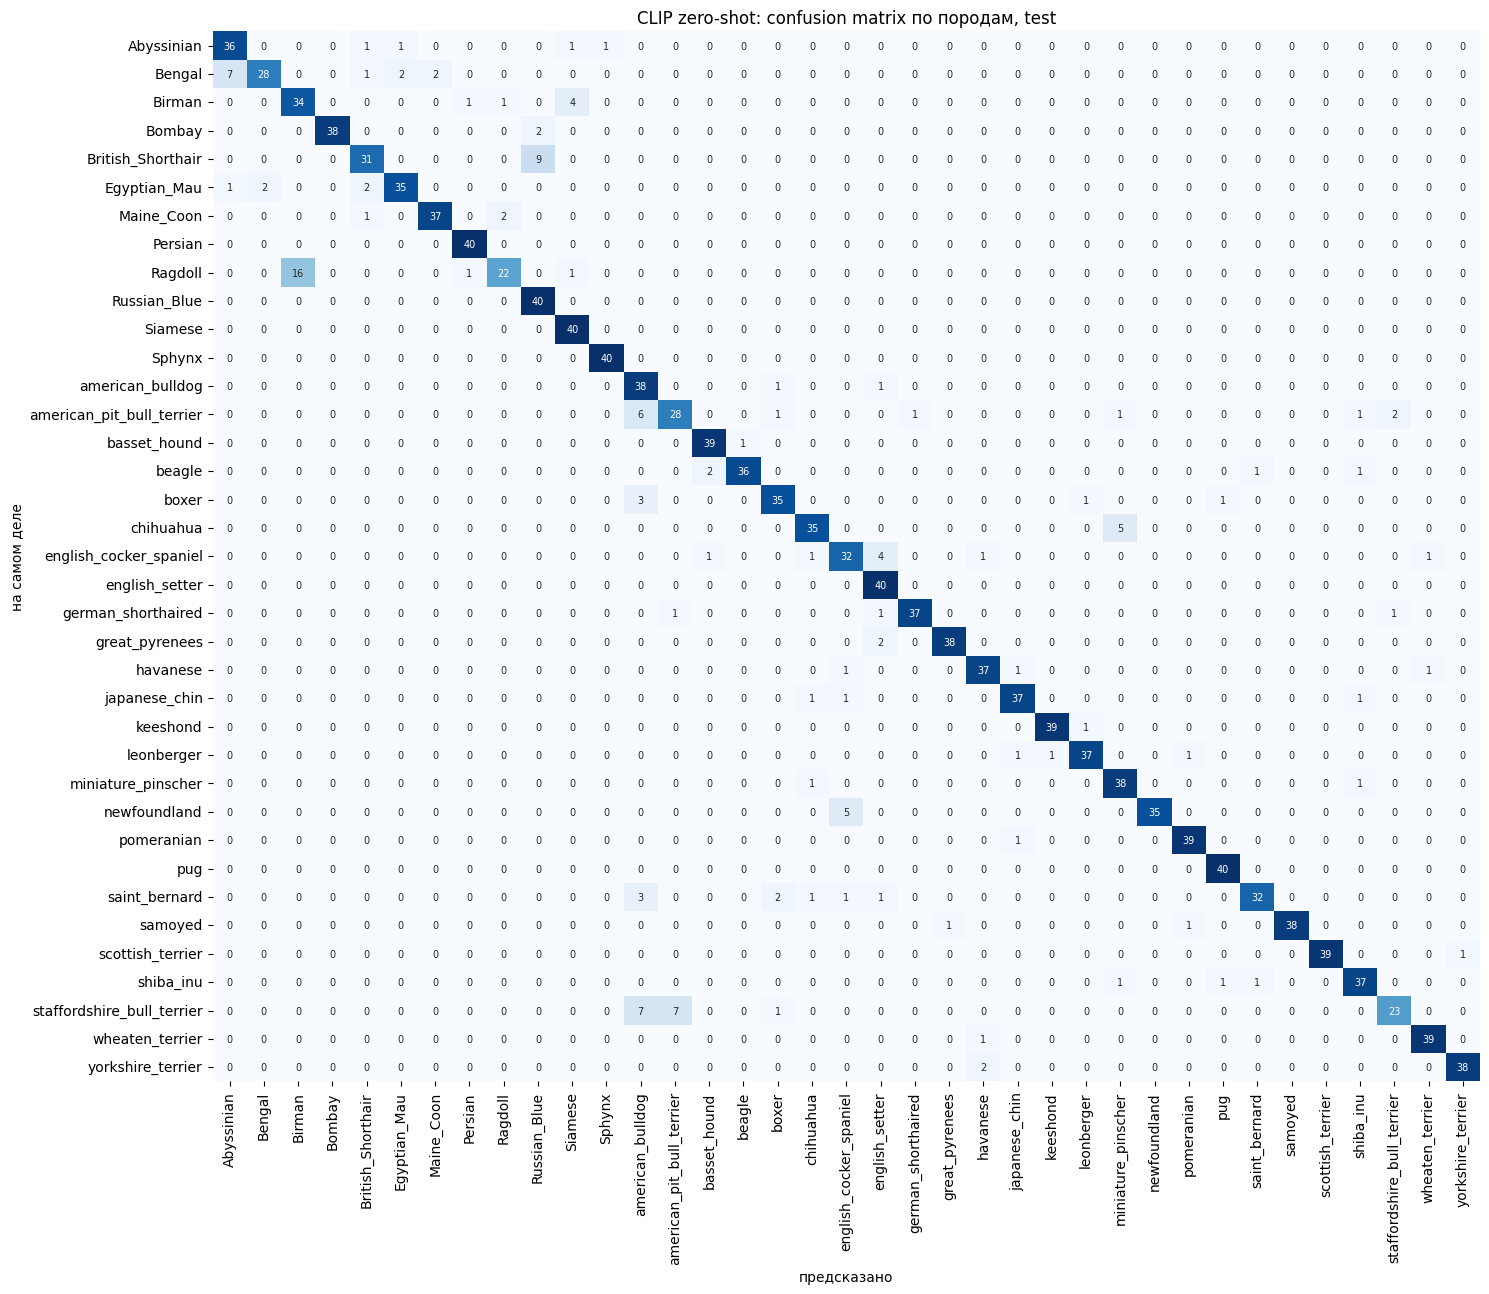

Самые частые ошибки CLIP:


,настоящая порода,предсказана как,сколько раз
0,Ragdoll,Birman,16
1,British_Shorthair,Russian_Blue,9
2,staffordshire_bull_terrier,american_bulldog,7
3,Bengal,Abyssinian,7
4,staffordshire_bull_terrier,american_pit_bull_terrier,7
5,american_pit_bull_terrier,american_bulldog,6
6,newfoundland,english_cocker_spaniel,5
7,chihuahua,miniature_pinscher,5
8,english_cocker_spaniel,english_setter,4
9,Birman,Siamese,4


In [50]:
clip_cm = confusion_matrix(clip_targets.numpy(), clip_pred.numpy(), labels=np.arange(num_classes))
plot_confusion(clip_cm, classes, 'CLIP zero-shot: confusion matrix по породам, test')

print('Самые частые ошибки CLIP:')
display(most_confused(clip_cm, classes))

### 6.3. Влияние формулировки промпта

Zero-shot классификация чувствительна к тексту промпта. Сравним несколько шаблонов на тех же признаках изображений (изображения перекодировать не нужно — меняется только текст).

In [51]:
templates = {
    '{breed}': lambda b, s: b,
    'a photo of a {breed}': lambda b, s: f'a photo of a {b}',
    'a photo of a {breed}, a type of pet': lambda b, s: f'a photo of a {b}, a type of pet',
    'a photo of a {breed} {cat/dog}, a type of pet': lambda b, s: f'a photo of a {b} {s}, a type of pet',
}
rows = []
for template, make in templates.items():
    prompts = [make(classes[c].replace('_', ' '), SPECIES_NAMES[species[c]]) for c in range(num_classes)]
    scores = image_features @ encode_texts(prompts).cpu().T
    rows.append({'шаблон промпта': template,
                 'top-1': round((scores.argmax(1) == clip_targets).float().mean().item(), 4),
                 'top-3': round(topk_accuracy(scores, clip_targets, 3), 4)})
prompt_table = pd.DataFrame(rows)
display(prompt_table)

,шаблон промпта,top-1,top-3
0,{breed},0.7936,0.9181
1,a photo of a {breed},0.8288,0.9574
2,"a photo of a {breed}, a type of pet",0.8796,0.9763
3,"a photo of a {breed} {cat/dog}, a type of pet",0.8978,0.9871


## 7. Итоговые таблицы

Ячейка ниже печатает готовые таблицы в формате Markdown — их можно скопировать в `REPORT.md`.

In [52]:
print('| Сеть | Test accuracy | Top-3 | Top-5 | Обучаемых параметров |')
print('|---|---|---|---|---|')
for name, r in results.items():
    mark = ' (лучшая)' if name == best_name else ''
    print(f'| {name}{mark} | {r["test_acc"]:.3f} | {topk_accuracy(r["logits"], r["targets"], 3):.3f} | '
          f'{topk_accuracy(r["logits"], r["targets"], 5):.3f} | {r["trainable"]:,} |')
print()
print(f'| Метрика (Oxford Pets, test) | {best_name} (transfer learning) | CLIP ViT-B/32 (zero-shot) |')
print('|---|---|---|')
print(f'| Точность по породам (top-1) | {best_acc:.3f} | {clip_acc:.3f} |')
print(f'| Top-3 accuracy | {best_top3:.3f} | {clip_top3:.3f} |')
print(f'| Top-5 accuracy | {best_top5:.3f} | {clip_top5:.3f} |')
print(f'| Кошки против собак | {best_binary:.3f} | {clip_binary_acc:.3f} |')

| Сеть | Test accuracy | Top-3 | Top-5 | Обучаемых параметров |
|---|---|---|---|---|
| vgg16 | 0.922 | 0.995 | 0.999 | 151,589 |
| vgg19 | 0.917 | 0.995 | 0.999 | 151,589 |
| resnet50 (лучшая) | 0.923 | 0.994 | 0.997 | 75,813 |

| Метрика (Oxford Pets, test) | resnet50 (transfer learning) | CLIP ViT-B/32 (zero-shot) |
|---|---|---|
| Точность по породам (top-1) | 0.923 | 0.898 |
| Top-3 accuracy | 0.994 | 0.987 |
| Top-5 accuracy | 0.997 | 0.996 |
| Кошки против собак | 0.997 | 0.999 |
